# Notebook 14 — Peak Performance Results

**Hyperparameter-optimisation experiment · Soccer Event Transformer · Track A model family**

| Item | Content |
|---|---|
| **Question** | How much predictive performance can be obtained from the Track A model family before more capacity or training compute stops paying off? |
| **Purpose of this notebook** | Assemble the comparison tables and performance curves of the whole hyperparameter-optimisation experiment from its saved result files, and state the answer the measurements support. |
| **Experiment in brief** | A capacity sweep (23 architectures, seeds 0–1, Track A training setting), a training-hyperparameter search on the two best architectures (seeds 0–1), a five-seed benchmark of the six shortlisted architectures at the tuned setting (seeds 10–14), selection of the smallest architecture within noise of the best (4L_2H_K16), and final training of that architecture (seeds 100–104) with one test evaluation. |
| **Training performed** | None. No test evaluation either: the test numbers are read from `results/13_test_results.json`, written once when the test split was unlocked. |
| **Outputs** | `results/14_table1_all_configurations.csv` to `results/14_table5_baseline_vs_optimised.csv`, `results/14_table4b_best_versus_candidates.csv`, `results/14_final_report.json`, `results/14_integrity_check.json`, figures in `figures/`. |


In [ ]:
# ---------------------------------------------------------------------------
# Environment setup (identical at the top of every notebook of this experiment)
# ---------------------------------------------------------------------------
import os
import sys
import json
import time
import math
import copy
import hashlib
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")

PROJECT_DIR = Path(os.environ.get("TRACK_A_DIR", "/content/drive/MyDrive/soccer_mi/track_a"))
RUN_MODE = os.environ.get("TRACK_A_RUN_MODE", "full")
assert RUN_MODE in ("full", "smoke")
os.chdir(PROJECT_DIR)
if str(PROJECT_DIR) not in sys.path:
    sys.path.insert(0, str(PROJECT_DIR))

EXISTING_DIR = PROJECT_DIR if RUN_MODE == "full" else PROJECT_DIR / "smoke"
ARTIFACTS_DIR = PROJECT_DIR / "artifacts"
EXISTING_RUNS_DIR = EXISTING_DIR / "runs"
EXISTING_RESULTS_DIR = EXISTING_DIR / "results"
EXISTING_FROZEN_CONFIG = EXISTING_DIR / "config" / "frozen_config.json"

OPT_DIR = EXISTING_DIR / "experiments" / "hyperparameter_optimisation"
RUNS_DIR = OPT_DIR / "runs"
RESULTS_DIR = OPT_DIR / "results"
FIGURES_DIR = OPT_DIR / "figures"
CONFIG_DIR = OPT_DIR / "config"
MANIFEST_DIR = OPT_DIR / "manifests"
LOG_DIR = OPT_DIR / "logs"
for folder in [RUNS_DIR, RESULTS_DIR, FIGURES_DIR, CONFIG_DIR, MANIFEST_DIR, LOG_DIR]:
    folder.mkdir(parents=True, exist_ok=True)
MANIFEST_PATH = MANIFEST_DIR / "experiment_manifest.jsonl"


def file_sha256(path):
    digest = hashlib.sha256()
    with open(path, "rb") as handle:
        for chunk in iter(lambda: handle.read(1 << 20), b""):
            digest.update(chunk)
    return digest.hexdigest()


print("Colab:", IN_COLAB, "| RUN_MODE:", RUN_MODE)
print("Track A project (read-only):", EXISTING_DIR)
print("Experiment outputs:", OPT_DIR)

Mounted at /content/drive
Colab: True | RUN_MODE: full
Track A project (read-only): /content/drive/MyDrive/soccer_mi/track_a
Experiment outputs: /content/drive/MyDrive/soccer_mi/track_a/experiments/hyperparameter_optimisation


In [ ]:
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
import importlib

import src.data as data
import src.batching as batching
import src.metrics as metrics
import src.model as model_module
import src.mlp_baseline as mlp_baseline
import src.training as training
import src.analysis as analysis
for module in [data, batching, metrics, model_module, mlp_baseline, training, analysis]:
    importlib.reload(module)

plt.rcParams["figure.dpi"] = 110
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3
pd.set_option("display.width", 240)
pd.set_option("display.max_columns", 60)

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
if RUN_MODE == "full" and DEVICE != "cuda":
    raise RuntimeError("BLOCKED: full-mode training requires a GPU. In Colab: Runtime > Change runtime type > GPU.")

events = pd.read_parquet(ARTIFACTS_DIR / "events_prepared.parquet")
targets = events["action_id"].to_numpy().astype("int64")
match_ids = events["match_id"].to_numpy()

with open(EXISTING_FROZEN_CONFIG) as handle:
    TRACK_A_FROZEN = json.load(handle)

ENCODING = TRACK_A_FROZEN["encoding"]
POSSESSION_FEATURES = TRACK_A_FROZEN["possession_features"]
STRIDE = TRACK_A_FROZEN["stride"]

BASE_LAYERS = TRACK_A_FROZEN["model"]["n_layers"]
BASE_HEADS = TRACK_A_FROZEN["model"]["n_heads"]
BASE_D_MODEL = TRACK_A_FROZEN["model"]["d_model"]
BASE_D_FF = TRACK_A_FROZEN["model"]["d_ff"]
BASE_CONTEXT = TRACK_A_FROZEN["context_length"]
BASE_LR = TRACK_A_FROZEN["training"]["learning_rate"]
BASE_WD = TRACK_A_FROZEN["training"]["weight_decay"]
EPOCH_BUDGET = TRACK_A_FROZEN["training"]["max_epochs"]

print("Events:", len(events), "| device:", DEVICE)
print("Track A reference configuration:",
      f"L{BASE_LAYERS} H{BASE_HEADS} d_model {BASE_D_MODEL} d_ff {BASE_D_FF} K{BASE_CONTEXT}",
      f"| lr {BASE_LR:g} wd {BASE_WD:g} | epoch budget {EPOCH_BUDGET}")

Events: 658905 | device: cuda
Track A reference configuration: L2 H2 d_model 128 d_ff 512 K16 | lr 0.0003 wd 0.1 | epoch budget 30


In [ ]:
SHORT_NAME = {"batch_size": "bs", "warmup_fraction": "wu"}


def transformer_config(seed, n_layers, n_heads, context_length, d_model=None, d_ff=None,
                       learning_rate=None, weight_decay=None, max_epochs=None):
    """Build a run configuration in exactly the format used by the Track A notebooks."""
    model = {"n_layers": n_layers, "n_heads": n_heads,
             "d_model": BASE_D_MODEL if d_model is None else d_model,
             "d_ff": BASE_D_FF if d_ff is None else d_ff}
    training_settings = {"learning_rate": BASE_LR if learning_rate is None else learning_rate,
                         "weight_decay": BASE_WD if weight_decay is None else weight_decay,
                         "max_epochs": EPOCH_BUDGET if max_epochs is None else max_epochs}
    return {"model_type": "transformer", "encoding": ENCODING, "possession_features": POSSESSION_FEATURES,
            "context_length": context_length, "stride": STRIDE, "seed": seed,
            "model": model, "training": training_settings}


def architecture_label(config):
    """Readable architecture name, e.g. L4-H2-K16-D128-F512."""
    model = config["model"]
    return (f"L{model['n_layers']}-H{model['n_heads']}-K{config['context_length']}"
            f"-D{model['d_model']}-F{model['d_ff']}")


def variant_tag(training_settings):
   """Sub-folder for training settings that training.run_name_for() does not encode.

    run_name_for() encodes the learning rate, weight decay, architecture, context length and
    seed, but not the batch size or the warm-up fraction. To prevent runs that differ only in those
    two settings (batch size or the warm-up fraction) to be written to the same folder.
    """
    parts = []
    for key in ["batch_size", "warmup_fraction"]:
        if key in training_settings and training_settings[key] != training.DEFAULT_TRAINING[key]:
            parts.append(f"{SHORT_NAME[key]}{training_settings[key]:g}")
    return "_".join(parts) if parts else "base"


_BUNDLES = {}


def bundle_for(context_length):
    """Encoded data and evaluation views for one context length (built once, then reused)."""
    if context_length not in _BUNDLES:
        _BUNDLES[context_length] = training.prepare_data(
            events, ARTIFACTS_DIR, ENCODING, POSSESSION_FEATURES, context_length, STRIDE, DEVICE, RUN_MODE)
    return _BUNDLES[context_length]


def parameter_count(config):
    """Total parameters of a configuration, without training it."""
    model = training.build_model(config, bundle_for(config["context_length"])["vocabulary_sizes"])
    return model_module.count_parameters(model)["total"]


def run_one(config, extra_training=None, keep_every_epoch=False, verbose=True):
    """Train one configuration (or reload it if its folder already holds a finished run).

    Returns (run_dir, final_results). Nothing outside RUNS_DIR is written.
    """
    config = copy.deepcopy(config)
    if extra_training:
        config["training"].update(extra_training)
    runs_root = RUNS_DIR / variant_tag(config["training"])
    runs_root.mkdir(parents=True, exist_ok=True)
    result = training.train_run(config, bundle_for(config["context_length"]), runs_root,
                                MANIFEST_PATH, keep_every_epoch=keep_every_epoch, verbose=verbose)
    return runs_root / training.run_name_for(config), result


def result_row(config, run_dir, result, group=""):
    """One flat record per run, holding every quantity the later notebooks need."""
    val = result["val_metrics"]
    training_settings = result["training_settings"]
    return {
        "group": group,
        "architecture": architecture_label(config),
        "n_layers": config["model"]["n_layers"],
        "n_heads": config["model"]["n_heads"],
        "d_head": config["model"]["d_model"] // config["model"]["n_heads"],
        "d_model": config["model"]["d_model"],
        "d_ff": config["model"]["d_ff"],
        "context_length": config["context_length"],
        "learning_rate": training_settings["learning_rate"],
        "weight_decay": training_settings["weight_decay"],
        "batch_size": training_settings["batch_size"],
        "warmup_fraction": training_settings["warmup_fraction"],
        "seed": config["seed"],
        "parameters": result["parameter_counts"]["total"],
        "trainable_parameters": result["parameter_counts"].get("trainable", result["parameter_counts"]["total"]),
        "val_nll": val["nll"],
        "val_accuracy": val["accuracy"],
        "val_macro_f1": val["macro_f1"],
        "val_top3": val["top3_accuracy"],
        "val_top5": val["top5_accuracy"],
        "val_ece": val["ece"],
        "train_nll": result["train_nll"],
        "best_epoch": result["best_epoch"],
        "epochs_run": result["epochs_run"],
        "stopped_early": result["stopped_early"],
        "diverged": result["diverged"],
        "runtime_seconds": result["runtime_seconds"],
        "run_dir": str(run_dir),
        "run_name": result["run_name"],
    }


def append_results(rows, csv_path):
    """Append run records to a CSV, keeping one row per run name and variant folder."""
    table = pd.DataFrame(rows)
    if Path(csv_path).exists():
        table = pd.concat([pd.read_csv(csv_path), table], ignore_index=True)
    table = table.drop_duplicates(subset=["run_dir"], keep="last").reset_index(drop=True)
    table.to_csv(csv_path, index=False)
    return table


def seed_level_to_config_level(table):
    """Average the seed-level records of each configuration into one row per configuration."""
    keys = ["group", "architecture", "n_layers", "n_heads", "d_head", "d_model", "d_ff",
            "context_length", "learning_rate", "weight_decay", "batch_size", "warmup_fraction",
            "parameters"]
    summary = table.groupby(keys, as_index=False, sort=False).agg(
        n_seeds=("seed", "count"),
        val_nll=("val_nll", "mean"),
        val_nll_sd=("val_nll", "std"),
        val_accuracy=("val_accuracy", "mean"),
        val_accuracy_sd=("val_accuracy", "std"),
        val_macro_f1=("val_macro_f1", "mean"),
        val_top3=("val_top3", "mean"),
        val_top5=("val_top5", "mean"),
        val_ece=("val_ece", "mean"),
        train_nll=("train_nll", "mean"),
        best_epoch=("best_epoch", "mean"),
        runtime_seconds=("runtime_seconds", "mean"),
    )
    return summary.sort_values("val_nll").reset_index(drop=True)


def run_dirs_for(table, **conditions):
    """All run directories in a results table that match the given column values."""
    selected = table
    for column, value in conditions.items():
        selected = selected[selected[column] == value]
    return [Path(path) for path in selected["run_dir"]]


print("Helper functions defined.")

Helper functions defined.


## 1. Inputs



In [ ]:
paths = {
    "capacity runs": RESULTS_DIR / "08_capacity_runs.csv",
    "search runs": RESULTS_DIR / "09_hyperparameter_runs.csv",
    "profile": RESULTS_DIR / "08_profile.csv",
    "frontier": RESULTS_DIR / "10_frontier.csv",
    "marginal returns": RESULTS_DIR / "10_marginal_returns.csv",
    "elbow report": RESULTS_DIR / "10_elbow_report.json",
    "seed runs": RESULTS_DIR / "11_seed_runs.csv",
    "seed summary": RESULTS_DIR / "11_seed_summary.csv",
    "selected config": RESULTS_DIR / "12_selected_config.json",
    "final runs": RESULTS_DIR / "13_final_runs.csv",
    "test results": RESULTS_DIR / "13_test_results.json",
}
available = {name: path for name, path in paths.items() if path.exists()}
for name, path in paths.items():
    print(f"  {'found  ' if name in available else 'MISSING'} {name:20s} {path.name}")
for required in ["capacity runs", "seed summary", "selected config", "test results"]:
    if required not in available:
        raise RuntimeError(f"BLOCKED: {required} is missing. Run the earlier notebooks first.")

capacity_runs = pd.read_csv(paths["capacity runs"])
search_runs = pd.read_csv(paths["search runs"]) if "search runs" in available else pd.DataFrame(columns=capacity_runs.columns)
profile_table = pd.read_csv(paths["profile"]) if "profile" in available else pd.DataFrame(columns=["architecture"])
seed_summary = pd.read_csv(paths["seed summary"])
seed_runs = pd.read_csv(paths["seed runs"])
final_runs = pd.read_csv(paths["final runs"]) if "final runs" in available else pd.DataFrame()
selected_config = json.load(open(paths["selected config"]))
test_results = json.load(open(paths["test results"]))
elbow_report = json.load(open(paths["elbow report"])) if "elbow report" in available else {}
frontier = pd.read_csv(paths["frontier"]) if "frontier" in available else pd.DataFrame()
marginal = pd.read_csv(paths["marginal returns"]) if "marginal returns" in available else pd.DataFrame()

all_runs = pd.concat([capacity_runs, search_runs, seed_runs], ignore_index=True)
all_runs = all_runs.drop_duplicates(subset=["run_dir"], keep="last")
print(f"\nTotal runs across the experiment: {len(all_runs)}")
print(f"Total training time: {all_runs['runtime_seconds'].sum() / 3600:.2f} GPU-hours")

  found   capacity runs        08_capacity_runs.csv
  found   search runs          09_hyperparameter_runs.csv
  found   profile              08_profile.csv
  found   frontier             10_frontier.csv
  found   marginal returns     10_marginal_returns.csv
  found   elbow report         10_elbow_report.json
  found   seed runs            11_seed_runs.csv
  found   seed summary         11_seed_summary.csv
  found   selected config      12_selected_config.json
  found   final runs           13_final_runs.csv
  found   test results         13_test_results.json

Total runs across the experiment: 119
Total training time: 4.61 GPU-hours


## 2. Table 1 — every configuration tested

One row per configuration, averaged over the seeds it was trained with. A "configuration" here is an architecture together with its training setting and the stage it was trained in, so the same architecture can appear in several rows (for example L6-H2-K16 at different learning rates, weight decays and batch sizes, and again in the five-seed benchmark). Configurations trained with one seed have an empty SD column.

In [ ]:
usable = all_runs[~all_runs["diverged"]]
table1 = seed_level_to_config_level(usable)
table1 = table1.merge(profile_table[["architecture", "peak_gpu_memory_mb"]].drop_duplicates("architecture"),
                      on="architecture", how="left")
table1 = table1.rename(columns={
    "architecture": "Model", "n_layers": "Layers", "n_heads": "Heads", "context_length": "K",
    "d_model": "d_model", "d_ff": "d_ff", "parameters": "Params", "learning_rate": "LR",
    "weight_decay": "WD", "batch_size": "Batch", "warmup_fraction": "Warm-up", "n_seeds": "Seeds",
    "val_nll": "Val NLL", "val_nll_sd": "Val NLL SD", "val_accuracy": "Val Acc",
    "val_macro_f1": "Macro-F1", "val_top3": "Top-3", "val_top5": "Top-5", "val_ece": "ECE",
    "best_epoch": "Best epoch", "runtime_seconds": "Runtime (s)",
    "peak_gpu_memory_mb": "Peak GPU MB"})
TABLE1_COLUMNS = ["Model", "Layers", "Heads", "K", "d_model", "d_ff", "Params", "LR", "WD", "Batch",
                  "Warm-up", "Seeds", "Val NLL", "Val NLL SD", "Val Acc", "Macro-F1", "Top-3",
                  "Top-5", "ECE", "Best epoch", "Runtime (s)", "Peak GPU MB"]
table1 = table1[TABLE1_COLUMNS]
table1.to_csv(RESULTS_DIR / "14_table1_all_configurations.csv", index=False)

diverged_count = int(all_runs["diverged"].sum())
print(f"Configurations in table 1: {len(table1)} | runs excluded for divergence: {diverged_count}")
table1.round(4)

Configurations in table 1: 60 | runs excluded for divergence: 0


,Model,Layers,Heads,K,d_model,d_ff,Params,LR,WD,Batch,Warm-up,Seeds,Val NLL,Val NLL SD,Val Acc,Macro-F1,Top-3,Top-5,ECE,Best epoch,Runtime (s),Peak GPU MB
0,L6-H2-K16-D128-F512,6,2,16,128,512,1307663,0.0003,0.01,128,0.05,1,0.9001,NaN,0.6240,0.5509,0.9479,0.9943,0.0110,5.0,193.8860,723.3004
1,L8-H2-K16-D128-F512,8,2,16,128,512,1704207,0.0003,0.01,256,0.05,5,0.9010,0.0005,0.6218,0.5618,0.9482,0.9946,0.0167,7.6,189.1478,797.9356
2,L6-H2-K16-D128-F512,6,2,16,128,512,1307663,0.0003,0.01,256,0.05,2,0.9014,0.0016,0.6224,0.5565,0.9485,0.9944,0.0181,7.5,133.1252,723.3004
3,L8-H2-K16-D128-F512,8,2,16,128,512,1704207,0.0003,0.10,256,0.05,1,0.9015,NaN,0.6234,0.5626,0.9480,0.9942,0.0282,9.0,198.9163,797.9356
4,L8-H2-K16-D128-F512,8,2,16,128,512,1704207,0.0010,0.10,128,0.05,1,0.9015,NaN,0.6222,0.5532,0.9478,0.9946,0.0178,5.0,245.3662,797.9356
5,L6-H2-K16-D128-F512,6,2,16,128,512,1307663,0.0003,0.10,256,0.05,2,0.9020,0.0020,0.6230,0.5566,0.9487,0.9944,0.0209,7.5,139.6421,723.3004
6,L6-H1-K16-D128-F512,6,1,16,128,512,1307663,0.0003,0.01,256,0.05,5,0.9021,0.0015,0.6218,0.5577,0.9483,0.9944,0.0170,7.2,139.0580,NaN
7,L6-H2-K16-D128-F512,6,2,16,128,512,1307663,0.0003,0.01,256,0.05,5,0.9025,0.0015,0.6223,0.5601,0.9485,0.9945,0.0164,6.8,138.5717,723.3004
8,L6-H1-K16-D128-F512,6,1,16,128,512,1307663,0.0003,0.10,256,0.05,2,0.9026,0.0001,0.6247,0.5615,0.9485,0.9944,0.0231,8.0,140.2174,NaN
9,L4-H2-K16-D128-F512,4,2,16,128,512,911119,0.0003,0.10,256,0.05,2,0.9027,0.0014,0.6227,0.5631,0.9481,0.9942,0.0198,8.0,105.9108,648.6651


**What the table contains.** 60 configurations from the capacity sweep, the hyperparameter search and the five-seed benchmark; no run was excluded for divergence. Columns: architecture, training setting, number of seeds, the six validation metrics, mean best epoch, mean runtime and measured peak GPU memory.

**How to read it.** The `Seeds` column matters for every row: a configuration trained once cannot be compared with one trained five times on the strength of the mean alone. The top row (L6-H2-K16 at batch 128, validation NLL 0.9001) is a single seed from the batch-size sensitivity check, which was not a comparison at equal compute and was not adopted. The lowest five-seed row is L8-H2-K16 at 0.9010.

## 3. Tables 2 and 3 — best configurations by each headline metric

The two orderings are shown separately rather than combined. They can disagree: NLL scores the whole predicted distribution, accuracy only whether the top-ranked class was right, so a configuration can win on one and not the other. Where they disagree, the disagreement is the result; no combined score is formed.

**RESULT.** The top 10 by NLL are all K = 16, d_model 128, d_ff 512 configurations with 4, 6 or 8 layers (NLL 0.9001–0.9027). The top 10 by accuracy are mostly 6-layer configurations (accuracy 0.6229–0.6247).

**How to read the overlap line.** The printed overlap counts architecture labels, not rows. Because the same architecture appears with several training settings, "3 in both" means three architecture labels occur in both top-10 lists; L4-H2-K16 appears only in the NLL list and L6-H4-K16 only in the accuracy list.


In [ ]:
DISPLAY_COLUMNS = ["Model", "Layers", "Heads", "K", "d_model", "d_ff", "Params", "LR", "WD",
                   "Seeds", "Val NLL", "Val NLL SD", "Val Acc", "Macro-F1", "Top-3", "Top-5", "ECE",
                   "Runtime (s)"]
TOP_N = 10

table2 = table1.sort_values("Val NLL").head(TOP_N)[DISPLAY_COLUMNS].reset_index(drop=True)
table3 = table1.sort_values("Val Acc", ascending=False).head(TOP_N)[DISPLAY_COLUMNS].reset_index(drop=True)
table2.to_csv(RESULTS_DIR / "14_table2_best_by_val_nll.csv", index=False)
table3.to_csv(RESULTS_DIR / "14_table3_best_by_val_accuracy.csv", index=False)

top_by_nll = set(table2["Model"])
top_by_accuracy = set(table3["Model"])
print(f"Configurations in the top {TOP_N} of both orderings: {len(top_by_nll & top_by_accuracy)}")
print(f"Top by NLL only:      {sorted(top_by_nll - top_by_accuracy)}")
print(f"Top by accuracy only: {sorted(top_by_accuracy - top_by_nll)}")
print("\nTable 2 — best by validation NLL")
print(table2.round(4).to_string(index=False))
print("\nTable 3 — best by validation accuracy")
print(table3.round(4).to_string(index=False))

Configurations in the top 10 of both orderings: 3
Top by NLL only:      ['L4-H2-K16-D128-F512']
Top by accuracy only: ['L6-H4-K16-D128-F512']

Table 2 — best by validation NLL
              Model  Layers  Heads  K  d_model  d_ff  Params     LR   WD  Seeds  Val NLL  Val NLL SD  Val Acc  Macro-F1  Top-3  Top-5    ECE  Runtime (s)
L6-H2-K16-D128-F512       6      2 16      128   512 1307663 0.0003 0.01      1   0.9001         NaN   0.6240    0.5509 0.9479 0.9943 0.0110     193.8860
L8-H2-K16-D128-F512       8      2 16      128   512 1704207 0.0003 0.01      5   0.9010      0.0005   0.6218    0.5618 0.9482 0.9946 0.0167     189.1478
L6-H2-K16-D128-F512       6      2 16      128   512 1307663 0.0003 0.01      2   0.9014      0.0016   0.6224    0.5565 0.9485 0.9944 0.0181     133.1252
L8-H2-K16-D128-F512       8      2 16      128   512 1704207 0.0003 0.10      1   0.9015         NaN   0.6234    0.5626 0.9480 0.9942 0.0282     198.9163
L8-H2-K16-D128-F512       8      2 16      128   512 1

## 4. Table 4 — five-seed benchmark of the candidates

Eight candidates, each trained with seeds 10–14: the six shortlisted architectures at the tuned setting (learning rate 3e-4, weight decay 0.01; role `benchmark`), the frozen Track A configuration (weight decay 0.1; role `reference`) and 6L_2H_K16 at weight decay 0.1 (role `tuning check`).

In [ ]:
table4 = seed_summary.rename(columns={
    "candidate": "Candidate", "role": "Role", "architecture": "Model", "parameters": "Params",
    "learning_rate": "LR", "weight_decay": "WD", "n_seeds": "Seeds",
    "val_nll_mean": "Val NLL mean", "val_nll_sd": "Val NLL SD", "val_nll_min": "Val NLL min",
    "val_nll_max": "Val NLL max", "val_nll_range": "Val NLL range",
    "val_accuracy_mean": "Val Acc mean", "val_accuracy_sd": "Val Acc SD",
    "val_macro_f1_mean": "Macro-F1 mean", "val_macro_f1_sd": "Macro-F1 SD",
    "val_top3_mean": "Top-3 mean", "val_top5_mean": "Top-5 mean",
    "val_ece_mean": "ECE mean", "val_ece_sd": "ECE SD",
    "best_epoch_min": "Best epoch min", "best_epoch_max": "Best epoch max"})
TABLE4_COLUMNS = ["Candidate", "Role", "Model", "Params", "LR", "WD", "Seeds", "Val NLL mean", "Val NLL SD",
                  "Val NLL min", "Val NLL max", "Val NLL range", "Val Acc mean", "Val Acc SD",
                  "Macro-F1 mean", "Macro-F1 SD", "Top-3 mean", "Top-5 mean", "ECE mean", "ECE SD",
                  "Best epoch min", "Best epoch max"]
table4 = table4[TABLE4_COLUMNS]
table4.to_csv(RESULTS_DIR / "14_table4_seed_stability.csv", index=False)
table4.round(4)

,Candidate,Role,Model,Params,LR,WD,Seeds,Val NLL mean,Val NLL SD,Val NLL min,Val NLL max,Val NLL range,Val Acc mean,Val Acc SD,Macro-F1 mean,Macro-F1 SD,Top-3 mean,Top-5 mean,ECE mean,ECE SD,Best epoch min,Best epoch max
0,8L_2H_K16,benchmark,L8-H2-K16-D128-F512,1704207,0.0003,0.01,5,0.9010,0.0005,0.9005,0.9017,0.0012,0.6218,0.0014,0.5618,0.0021,0.9482,0.9946,0.0167,0.0067,6,10
1,6L_1H_K16,benchmark,L6-H1-K16-D128-F512,1307663,0.0003,0.01,5,0.9021,0.0015,0.8997,0.9037,0.0040,0.6218,0.0011,0.5577,0.0047,0.9483,0.9944,0.0170,0.0053,6,8
2,6L_2H_K16,benchmark,L6-H2-K16-D128-F512,1307663,0.0003,0.01,5,0.9025,0.0015,0.9001,0.9044,0.0043,0.6223,0.0015,0.5601,0.0024,0.9485,0.9945,0.0164,0.0052,6,8
3,6L_2H_K16 (Track A hyperparameters),tuning check,L6-H2-K16-D128-F512,1307663,0.0003,0.10,5,0.9031,0.0010,0.9018,0.9045,0.0027,0.6222,0.0014,0.5593,0.0081,0.9480,0.9944,0.0230,0.0069,8,10
4,4L_2H_K16,benchmark,L4-H2-K16-D128-F512,911119,0.0003,0.01,5,0.9036,0.0017,0.9016,0.9055,0.0039,0.6216,0.0015,0.5590,0.0033,0.9482,0.9944,0.0196,0.0045,7,9
5,6L_8H_K16,benchmark,L6-H8-K16-D128-F512,1307663,0.0003,0.01,5,0.9043,0.0017,0.9032,0.9072,0.0040,0.6215,0.0010,0.5600,0.0069,0.9480,0.9944,0.0199,0.0072,6,8
6,Track A reference,reference,L2-H2-K16-D128-F512,514575,0.0003,0.10,5,0.9069,0.0018,0.9052,0.9100,0.0048,0.6208,0.0021,0.5583,0.0029,0.9474,0.9941,0.0161,0.0048,6,8
7,2L_2H_K16,benchmark,L2-H2-K16-D128-F512,514575,0.0003,0.01,5,0.9070,0.0020,0.9049,0.9103,0.0054,0.6208,0.0017,0.5583,0.0029,0.9474,0.9941,0.0164,0.0045,6,8


**What the table contains.** For each candidate: mean, SD, minimum, maximum and range of validation NLL over the five seeds; mean and SD of accuracy and macro-F1; top-3, top-5; ECE mean and SD; the earliest and latest best epoch.

**RESULT.** Mean validation NLL ranges from 0.9010 (8L_2H_K16, SD 0.0005, range 0.0012) to 0.9070 (2L_2H_K16, SD 0.0020, range 0.0054). The selected configuration 4L_2H_K16 has 0.9036 (SD 0.0017, range 0.0039). The Track A reference has 0.9069 (SD 0.0018, range 0.0048).

**How to read it.** The range is the practical measure of how far one training run of a configuration can land from its own average. A difference between two candidates smaller than their ranges is not a property of the configurations.

### Table 4b — best benchmark configuration against every candidate

Read from `results/11_best_versus_candidates.csv`. One row per candidate: role, per-seed validation NLL, and the comparison with the benchmark configuration of lowest mean validation NLL under the decision rule.

**Decision rule ("better beyond noise").** A is better than B beyond noise only if (1) the 95% match-level bootstrap interval of the per-event NLL difference, computed on per-event validation NLL averaged over seeds, lies entirely below zero, **and** (2) every seed of A has a lower validation NLL than every seed of B. The `status` column records the outcome: "within noise of the best" (with "inconclusive" when the interval excludes zero but the seeds overlap) or "beaten beyond noise by the best".

The same candidates are shown seed by seed in `figures/11_fig1_nll_by_architecture.png` and `figures/11_fig2_accuracy_by_architecture.png`.

**RESULT.** Best: 8L_2H_K16. Within noise: 6L_1H_K16 (gap 0.0011, interval includes zero), 6L_2H_K16 and 4L_2H_K16 (intervals exclude zero, seeds overlap: inconclusive). Beaten beyond noise: 6L_8H_K16, 2L_2H_K16, the Track A reference and the tuning check.

In [ ]:
best_versus = pd.read_csv(RESULTS_DIR / "11_best_versus_candidates.csv")
best_versus.to_csv(RESULTS_DIR / "14_table4b_best_versus_candidates.csv", index=False)
best_versus[["candidate", "role", "parameters", "seeds", "mean val NLL", "NLL SD", "per-seed val NLL",
             "best - candidate", "gap 95% CI", "seeds separated", "beyond noise", "status"]].round(4)

,candidate,role,parameters,seeds,mean val NLL,NLL SD,per-seed val NLL,best - candidate,gap 95% CI,seeds separated,beyond noise,status
0,8L_2H_K16,benchmark,1704207,5,0.9010,0.0005,"[0.9007, 0.9009, 0.9005, 0.9017, 0.9011]",NaN,NaN,NaN,NaN,best benchmark configuration
1,6L_1H_K16,benchmark,1307663,5,0.9021,0.0015,"[0.9037, 0.9025, 0.902, 0.9024, 0.8997]",0.0011,"[-0.0004, 0.0027]",False,False,within noise of the best
2,6L_2H_K16,benchmark,1307663,5,0.9025,0.0015,"[0.9044, 0.9026, 0.9028, 0.9027, 0.9001]",0.0015,"[0.0003, 0.0027]",False,False,within noise of the best (inconclusive)
3,6L_2H_K16 (Track A hyperparameters),tuning check,1307663,5,0.9031,0.0010,"[0.9045, 0.9031, 0.9026, 0.9035, 0.9018]",0.0021,"[0.0005, 0.0038]",True,True,beaten beyond noise by the best
4,4L_2H_K16,benchmark,911119,5,0.9036,0.0017,"[0.9055, 0.9035, 0.9022, 0.9051, 0.9016]",0.0026,"[0.0013, 0.0040]",False,False,within noise of the best (inconclusive)
5,6L_8H_K16,benchmark,1307663,5,0.9043,0.0017,"[0.9072, 0.9033, 0.904, 0.904, 0.9032]",0.0033,"[0.0018, 0.0048]",True,True,beaten beyond noise by the best
6,Track A reference,reference,514575,5,0.9069,0.0018,"[0.9064, 0.9067, 0.9063, 0.91, 0.9052]",0.0059,"[0.0041, 0.0079]",True,True,beaten beyond noise by the best
7,2L_2H_K16,benchmark,514575,5,0.9070,0.0020,"[0.9066, 0.9067, 0.9064, 0.9103, 0.9049]",0.0060,"[0.0041, 0.0080]",True,True,beaten beyond noise by the best


## 5. Table 5 — frozen Track A model against the selected model

The first rows give the architecture and training hyperparameters of both models; the remaining rows give every headline metric on the locked test split (mean over five seeds each), on the 65,009 test events both models cover. In the table the selected model is labelled "Optimised model".

In [ ]:
headline = pd.DataFrame(test_results["headline"]).set_index("model")
track_a_validation = json.load(open(EXISTING_RESULTS_DIR / "06_validation_report.json"))
track_a_frozen = track_a_validation["frozen_config"]

optimised_validation = seed_summary[seed_summary["candidate"] == selected_config["selection"]["selected_candidate"]]
track_a_validation_row = seed_summary[seed_summary["candidate"] == "Track A reference"]

table5 = pd.DataFrame([
    {"Quantity": "Layers",
     "Track A model": track_a_frozen["model"]["n_layers"], "Optimised model": selected_config["model"]["n_layers"]},
    {"Quantity": "Heads",
     "Track A model": track_a_frozen["model"]["n_heads"], "Optimised model": selected_config["model"]["n_heads"]},
    {"Quantity": "Context length K",
     "Track A model": track_a_frozen["context_length"], "Optimised model": selected_config["context_length"]},
    {"Quantity": "d_model",
     "Track A model": track_a_frozen["model"]["d_model"], "Optimised model": selected_config["model"]["d_model"]},
    {"Quantity": "d_ff",
     "Track A model": track_a_frozen["model"]["d_ff"], "Optimised model": selected_config["model"]["d_ff"]},
    {"Quantity": "Learning rate",
     "Track A model": track_a_frozen["training"]["learning_rate"],
     "Optimised model": selected_config["training"]["learning_rate"]},
    {"Quantity": "Weight decay",
     "Track A model": track_a_frozen["training"]["weight_decay"],
     "Optimised model": selected_config["training"]["weight_decay"]},
    {"Quantity": "Parameters",
     "Track A model": track_a_validation["seed_summary"][0].get("parameters", "see Track A release"),
     "Optimised model": selected_config["parameter_counts"]["total"]},
    {"Quantity": "Test NLL",
     "Track A model": headline.loc["Track A model (frozen)", "NLL"],
     "Optimised model": headline.loc["Optimised model", "NLL"]},
    {"Quantity": "Test accuracy",
     "Track A model": headline.loc["Track A model (frozen)", "accuracy"],
     "Optimised model": headline.loc["Optimised model", "accuracy"]},
    {"Quantity": "Test macro-F1",
     "Track A model": headline.loc["Track A model (frozen)", "macro-F1"],
     "Optimised model": headline.loc["Optimised model", "macro-F1"]},
    {"Quantity": "Test top-3",
     "Track A model": headline.loc["Track A model (frozen)", "top-3"],
     "Optimised model": headline.loc["Optimised model", "top-3"]},
    {"Quantity": "Test top-5",
     "Track A model": headline.loc["Track A model (frozen)", "top-5"],
     "Optimised model": headline.loc["Optimised model", "top-5"]},
    {"Quantity": "Test ECE",
     "Track A model": headline.loc["Track A model (frozen)", "ECE"],
     "Optimised model": headline.loc["Optimised model", "ECE"]},
])
table5.to_csv(RESULTS_DIR / "14_table5_baseline_vs_optimised.csv", index=False)

print(table5.to_string(index=False))
print()
print(f"Difference in test NLL (optimised minus Track A): "
      f"{test_results['difference_optimised_minus_track_a']:+.4f} nats "
      f"[{test_results['difference_ci_low']:+.4f}, {test_results['difference_ci_high']:+.4f}]")
print(f"Seeds completely separated: {test_results['seeds_completely_separated']}")
print(f"Better beyond noise on test: {test_results['better_beyond_noise_on_test']}")
print(f"Test events compared: {test_results['n_test_events_compared']:,}")

        Quantity       Track A model  Optimised model
          Layers                   2         4.000000
           Heads                   2         2.000000
Context length K                  16        16.000000
         d_model                 128       128.000000
            d_ff                 512       512.000000
   Learning rate              0.0003         0.000300
    Weight decay                 0.1         0.010000
      Parameters see Track A release    911119.000000
        Test NLL            0.915847         0.914801
   Test accuracy            0.616069         0.617108
   Test macro-F1            0.557988         0.558519
      Test top-3            0.944475         0.943980
      Test top-5             0.99365         0.993641
        Test ECE            0.023758         0.027013

Difference in test NLL (optimised minus Track A): -0.0010 nats [-0.0027, +0.0006]
Seeds completely separated: False
Better beyond noise on test: False
Test events compared: 65,009


**RESULT.** The two models differ in depth (2 against 4 layers) and weight decay (0.1 against 0.01); heads, K, d_model, d_ff and learning rate are the same. The selected model has 911,119 parameters. On test: NLL 0.9158 (Track A) against 0.9148 (selected); accuracy 0.6161 against 0.6171; macro-F1 0.5580 against 0.5585; top-3 0.9445 against 0.9440; top-5 0.9937 against 0.9936; ECE 0.0238 against 0.0270.

Test NLL difference (selected − Track A): −0.0010 nats, 95% match-level bootstrap interval [−0.0027, +0.0006], seeds not separated: **not better beyond noise**.

**INTERPRETATION.** The test data do not distinguish the two models. The configuration rows show what was changed; because two things changed at once, the comparison does not attribute the small difference, which is not beyond noise, to either one.


## 6. Performance curves for the whole experiment

Three summary panels: capacity against validation NLL, training cost against validation NLL, and the marginal return of each step along the frontier.

**What is drawn from where.** The scatter points in the left and centre panels are all 60 configurations of Table 1, including the search and benchmark runs. The frontier line (left) and the marginal-return steps (right) are read from `results/10_frontier.csv` and `results/10_marginal_returns.csv`, which were computed from the 23 capacity-sweep configurations only (all at the Track A training setting). They are therefore not recomputed on the complete run set. The dashed reference line in the right panel is the median seed SD over Table 1 (0.0015 nats), not the capacity-sweep value (0.0012) used when the marginal returns were computed.

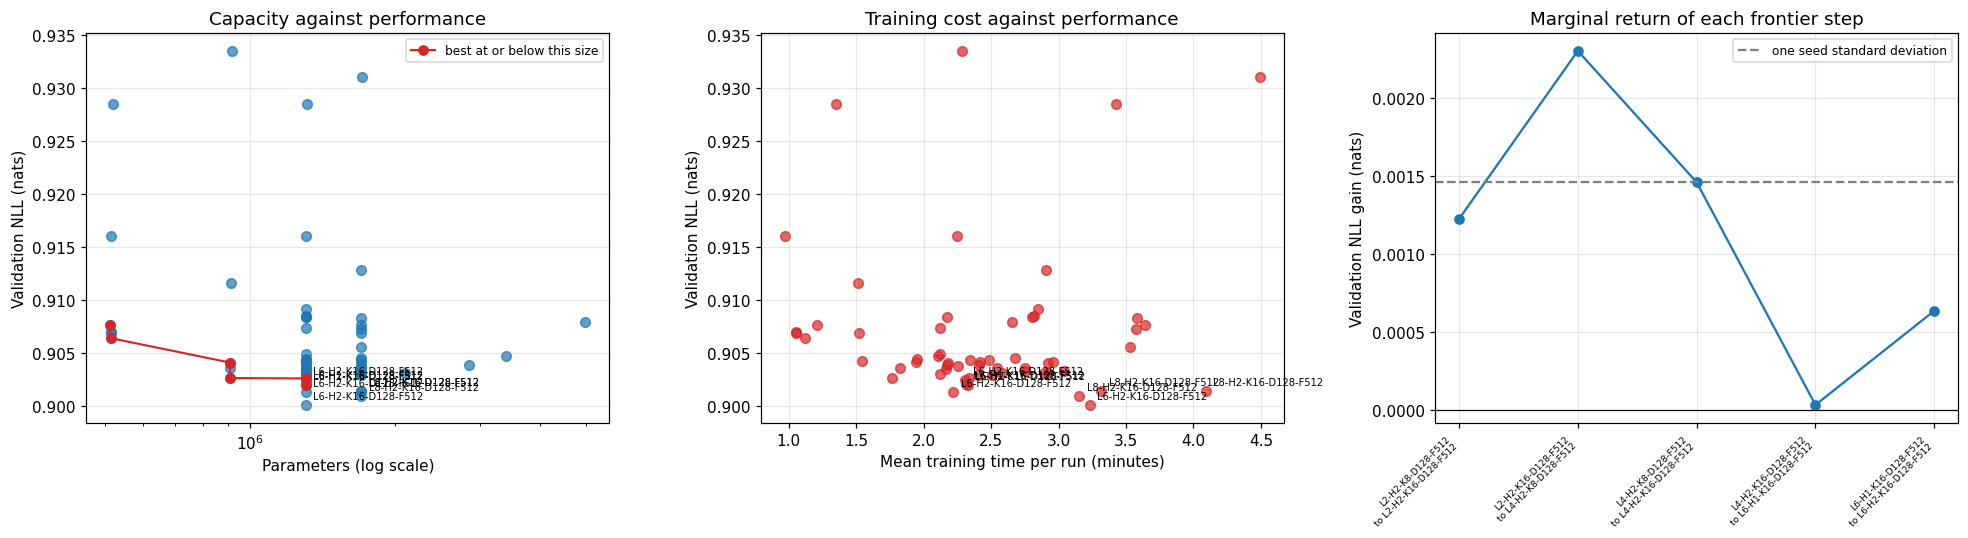

In [ ]:
seed_noise = float(table1["Val NLL SD"].median(skipna=True))

fig, axes = plt.subplots(1, 3, figsize=(18, 5.0))

axes[0].scatter(table1["Params"], table1["Val NLL"], s=40, alpha=0.7)
if len(frontier):
    axes[0].plot(frontier["parameters"], frontier["val_nll"], color="tab:red", marker="o",
                 linewidth=1.4, label="best at or below this size")
    axes[0].legend(fontsize=8)
for _, row in table1.sort_values("Val NLL").head(8).iterrows():
    axes[0].annotate(row["Model"], (row["Params"], row["Val NLL"]),
                     textcoords="offset points", xytext=(5, 4), fontsize=6.5)
axes[0].set_xscale("log")
axes[0].set_xlabel("Parameters (log scale)")
axes[0].set_ylabel("Validation NLL (nats)")
axes[0].set_title("Capacity against performance")

axes[1].scatter(table1["Runtime (s)"] / 60, table1["Val NLL"], s=40, alpha=0.7, color="tab:red")
for _, row in table1.sort_values("Val NLL").head(8).iterrows():
    axes[1].annotate(row["Model"], (row["Runtime (s)"] / 60, row["Val NLL"]),
                     textcoords="offset points", xytext=(5, 4), fontsize=6.5)
axes[1].set_xlabel("Mean training time per run (minutes)")
axes[1].set_ylabel("Validation NLL (nats)")
axes[1].set_title("Training cost against performance")

if len(marginal):
    axes[2].plot(range(len(marginal)), marginal["nll_gain"], marker="o", color="tab:blue")
    axes[2].axhline(seed_noise, color="tab:grey", linestyle="--", label="one seed standard deviation")
    axes[2].axhline(0.0, color="black", linewidth=0.8)
    axes[2].set_xticks(range(len(marginal)))
    axes[2].set_xticklabels([f"{row['from']}\nto {row['to']}" for _, row in marginal.iterrows()],
                            fontsize=6, rotation=45, ha="right")
    axes[2].set_ylabel("Validation NLL gain (nats)")
    axes[2].set_title("Marginal return of each frontier step")
    axes[2].legend(fontsize=8)
else:
    axes[2].text(0.5, 0.5, "No frontier data available", ha="center", va="center")
    axes[2].set_axis_off()
plt.tight_layout()
plt.savefig(FIGURES_DIR / "14_performance_curves.png", bbox_inches="tight")
plt.show()

**What are we looking at?** Left: validation NLL against parameter count (log scale) for every configuration, with the capacity-sweep frontier. Centre: validation NLL against mean training time per run. Right: the validation NLL gained at each step along the frontier, with one seed SD marked.

**What it shows.** The lowest NLLs are reached by configurations of 0.9M–1.7M parameters; the wider configurations (up to 4.97M) and the longer runs do not reach lower NLL. In the right panel the gains shrink after the step from 2 to 4 layers. Because the reference line here (0.0015) is higher than the one used when the steps were computed (0.0012), more steps fall below it than in the capacity-sweep analysis.

**What it means.** Over the range tested, capacity and compute beyond about 0.9M parameters (4 layers at K = 16) bought gains smaller than the effect of changing the seed.

**What we cannot conclude.** The frontier is built from two-seed means of the capacity sweep. It bounds the search range rather than locating a hard limit: no saturation point met the pre-stated condition (see Section 8).

## 7. Seed-stability figure

Left: the five-seed validation NLL distribution of each benchmark candidate. Right: the validation NLL of each of the five final training runs of the selected configuration (seeds 100–104), with their mean.

/tmp/ipykernel_1775/3790724797.py:5: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  axes[0].boxplot(groups, labels=order, widths=0.5)


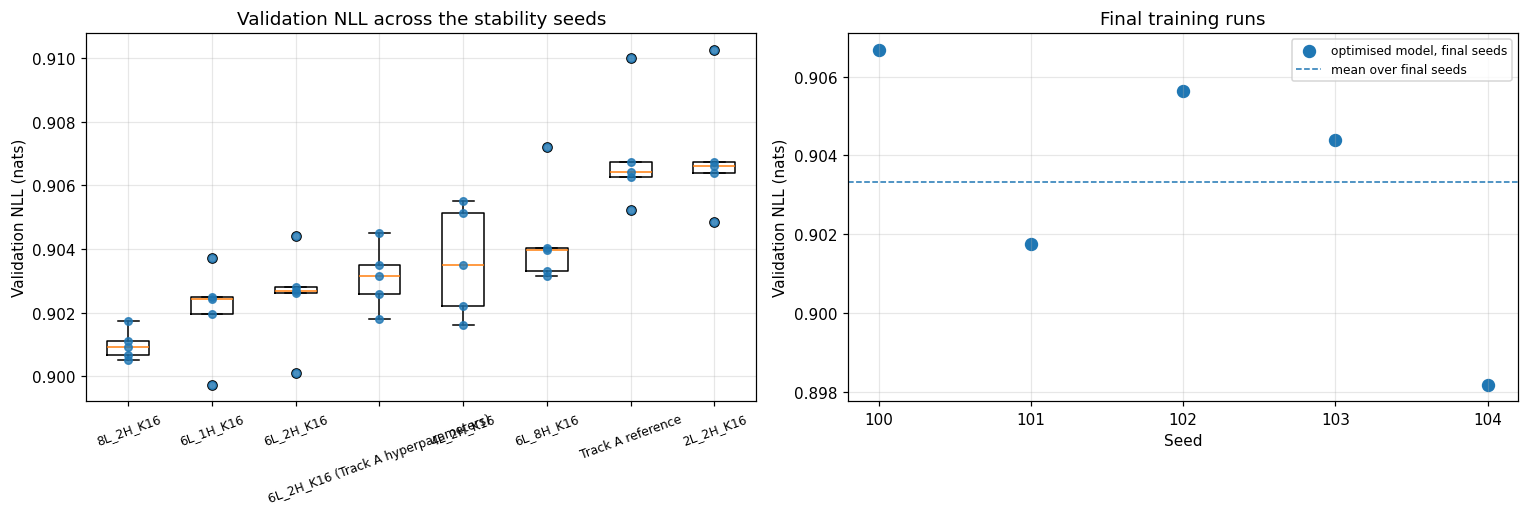

In [ ]:
order = list(seed_summary.sort_values("val_nll_mean")["candidate"])
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))

groups = [seed_runs[seed_runs["candidate"] == name]["val_nll"].to_numpy() for name in order]
axes[0].boxplot(groups, labels=order, widths=0.5)
for position, values in enumerate(groups, start=1):
    axes[0].scatter(np.full(len(values), position), values, s=24, alpha=0.8, color="tab:blue", zorder=3)
axes[0].set_ylabel("Validation NLL (nats)")
axes[0].set_title("Validation NLL across the stability seeds")
axes[0].tick_params(axis="x", labelrotation=20, labelsize=8)

if len(final_runs):
    axes[1].scatter(final_runs["seed"], final_runs["val_nll"], s=60, color="tab:blue",
                    label="optimised model, final seeds")
    axes[1].axhline(final_runs["val_nll"].mean(), color="tab:blue", linestyle="--", linewidth=1.0,
                    label="mean over final seeds")
    axes[1].set_xlabel("Seed")
    axes[1].set_ylabel("Validation NLL (nats)")
    axes[1].set_title("Final training runs")
    axes[1].set_xticks(final_runs["seed"])
    axes[1].legend(fontsize=8)
else:
    axes[1].text(0.5, 0.5, "No final runs recorded", ha="center", va="center")
    axes[1].set_axis_off()
plt.tight_layout()
plt.savefig(FIGURES_DIR / "14_seed_stability.png", bbox_inches="tight")
plt.show()

**What are we looking at?** Left: one box per candidate over seeds 10–14, with individual runs overlaid. Right: the five final runs of 4L_2H_K16 (seeds 100–104) and their mean (dashed).

**How to read it.** The right panel is a consistency check on the whole procedure. The final runs use a different set of seeds from the benchmark runs of the same configuration, so they should fall in about the same place as the 4L_2H_K16 box on the left. If they are spread more widely or centred elsewhere, the configuration is more seed-sensitive than the five-seed benchmark indicated, and conclusions based on one checkpoint of it should be held with correspondingly less confidence.



## 8. The answer the measurements support



In [ ]:
best_overall = table1.sort_values("Val NLL").iloc[0]
track_a_architecture = architecture_label(transformer_config(0, BASE_LAYERS, BASE_HEADS, BASE_CONTEXT))
track_a_in_table = table1[table1["Model"] == track_a_architecture]
validation_gain = (float(track_a_in_table.iloc[0]["Val NLL"]) - float(best_overall["Val NLL"])
                   if len(track_a_in_table) else None)

final_report = {
    "question": ("How much predictive performance can be obtained from the Track A model family "
                 "before additional capacity or training compute produces diminishing returns?"),
    "runs_performed": int(len(all_runs)),
    "configurations_tested": int(len(table1)),
    "gpu_hours": float(all_runs["runtime_seconds"].sum() / 3600),
    "seed_noise_reference_nats": seed_noise,
    "best_configuration_by_val_nll": str(best_overall["Model"]),
    "best_val_nll": float(best_overall["Val NLL"]),
    "track_a_val_nll_in_this_experiment": (float(track_a_in_table.iloc[0]["Val NLL"])
                                           if len(track_a_in_table) else None),
    "validation_gain_over_track_a_nats": validation_gain,
    "selected_configuration": selected_config["selection"]["selected_candidate"],
    "selected_architecture": (f"L{selected_config['model']['n_layers']}-"
                              f"H{selected_config['model']['n_heads']}-"
                              f"K{selected_config['context_length']}-"
                              f"D{selected_config['model']['d_model']}-"
                              f"F{selected_config['model']['d_ff']}"),
    "selected_parameters": int(selected_config["parameter_counts"]["total"]),
    "selected_training": selected_config["training"],
    "roles": selected_config.get("roles"),
    "replaces_track_a_on_validation": selected_config["selection"]["replaces_track_a"],
    "test_nll_difference": test_results["difference_optimised_minus_track_a"],
    "test_nll_ci": [test_results["difference_ci_low"], test_results["difference_ci_high"]],
    "better_beyond_noise_on_test": test_results["better_beyond_noise_on_test"],
    "saturation_point_supported": elbow_report.get("saturation_point_supported"),
    "saturation_point": (elbow_report.get("breakpoint_architecture")
                         if elbow_report.get("saturation_point_supported") else None),
}
training.save_json(RESULTS_DIR / "14_final_report.json", final_report)
print(json.dumps(final_report, indent=2, default=str))

{
  "question": "How much predictive performance can be obtained from the Track A model family before additional capacity or training compute produces diminishing returns?",
  "runs_performed": 119,
  "configurations_tested": 60,
  "gpu_hours": 4.609618648886681,
  "seed_noise_reference_nats": 0.0014612384329675365,
  "best_configuration_by_val_nll": "L6-H2-K16-D128-F512",
  "best_val_nll": 0.9001492857933044,
  "track_a_val_nll_in_this_experiment": 0.9064347743988038,
  "validation_gain_over_track_a_nats": 0.006285488605499379,
  "selected_configuration": "4L_2H_K16",
  "selected_architecture": "L4-H2-K16-D128-F512",
  "selected_parameters": 911119,
  "selected_training": {
    "learning_rate": 0.0003,
    "weight_decay": 0.01,
    "max_epochs": 30,
    "batch_size": 256,
    "warmup_fraction": 0.05,
    "min_lr_ratio": 0.1,
    "grad_clip": 1.0,
    "patience": 5
  },
  "roles": {
    "frozen_track_a_reference": "Track A reference",
    "best_predictive_configuration": "8L_2H_K16",
 

In [ ]:
lines = []
lines.append(f"The experiment trained {final_report['runs_performed']} runs covering "
             f"{final_report['configurations_tested']} configurations, using "
             f"{final_report['gpu_hours']:.1f} GPU-hours.")

if final_report["validation_gain_over_track_a_nats"] is None:
    lines.append("The Track A architecture does not appear in the combined table, so no direct "
                 "validation comparison is available here; the comparison in notebook 11 applies instead.")
else:
    lines.append(f"The best configuration found, {final_report['best_configuration_by_val_nll']}, reached a "
                 f"validation NLL of {final_report['best_val_nll']:.4f} against "
                 f"{final_report['track_a_val_nll_in_this_experiment']:.4f} for the Track A architecture, "
                 f"a difference of {final_report['validation_gain_over_track_a_nats']:.4f} nats. The "
                 f"reference scale for that difference is the median seed standard deviation of "
                 f"{final_report['seed_noise_reference_nats']:.4f} nats.")

if final_report["better_beyond_noise_on_test"]:
    lines.append(f"On the locked test split the optimised model improved on the frozen Track A model by "
                 f"{-final_report['test_nll_difference']:.4f} nats "
                 f"(95% interval [{-final_report['test_nll_ci'][1]:.4f}, {-final_report['test_nll_ci'][0]:.4f}]) "
                 f"with completely separated seeds, which satisfies the Track A decision rule.")
else:
    lines.append(f"On the locked test split the difference between the two models was "
                 f"{final_report['test_nll_difference']:+.4f} nats "
                 f"(95% interval [{final_report['test_nll_ci'][0]:+.4f}, {final_report['test_nll_ci'][1]:+.4f}]), "
                 f"which does not satisfy the Track A decision rule. The test data do not establish "
                 f"that the optimised model predicts held-out events better.")

if final_report["saturation_point_supported"]:
    lines.append(f"The frontier of validation NLL against model size supports a saturation point at "
                 f"{final_report['saturation_point']}: beyond that size the improvement per additional "
                 f"parameter falls sharply.")
elif final_report["saturation_point_supported"] is False:
    lines.append("The frontier does not support a distinct saturation point under the conditions stated "
                 "in notebook 10. The relationship between size and validation NLL is better described "
                 "as a steady decline over the range tested than as a curve with a knee, so the "
                 "experiment provides no evidence for a particular point at which additional capacity "
                 "stops paying.")
else:
    lines.append("The saturation analysis of notebook 10 was not available, so no statement about a "
                 "saturation point is made.")

for line in lines:
    print(line)
    print()
training.save_json(RESULTS_DIR / "14_final_statement.json", {"statement": lines})

The experiment trained 119 runs covering 60 configurations, using 4.6 GPU-hours.

The best configuration found, L6-H2-K16-D128-F512, reached a validation NLL of 0.9001 against 0.9064 for the Track A architecture, a difference of 0.0063 nats. The reference scale for that difference is the median seed standard deviation of 0.0015 nats.

On the locked test split the difference between the two models was -0.0010 nats (95% interval [-0.0027, +0.0006]), which does not satisfy the Track A decision rule. The test data do not establish that the optimised model predicts held-out events better.

The frontier does not support a distinct saturation point under the conditions stated in notebook 10. The relationship between size and validation NLL is better described as a steady decline over the range tested than as a curve with a knee, so the experiment provides no evidence for a particular point at which additional capacity stops paying.



## 9. Integrity check

The experiment was required to leave the Track A results untouched. The check re-fingerprints every Track A result and configuration file recorded before the capacity sweep started, reports any that changed, and prints the test-split unlocks recorded by this experiment.

In [ ]:
snapshot_path = MANIFEST_DIR / "track_a_snapshot.json"
modified = []
checked = 0
if snapshot_path.exists():
    for name, digest in json.load(open(snapshot_path)).items():
        path = EXISTING_DIR / name
        if path.exists():
            checked += 1
            if file_sha256(path) != digest:
                modified.append(name)

access_log = LOG_DIR / "test_access_log.jsonl"
accesses = [json.loads(line) for line in open(access_log)] if access_log.exists() else []

integrity = {
    "track_a_files_checked": checked,
    "track_a_files_modified": modified,
    "experiment_output_root": str(OPT_DIR),
    "test_split_unlocks": len(accesses),
    "test_unlock_records": accesses,
}
training.save_json(RESULTS_DIR / "14_integrity_check.json", integrity)
print(f"Track A files checked: {checked} | modified: {modified if modified else 'none'}")
print(f"Test-split unlocks recorded: {len(accesses)}")
for record in accesses:
    print(" ", record)

Track A files checked: 35 | modified: none
Test-split unlocks recorded: 1
  {'time': '2026-09-28T09:39:44.537057+00:00', 'frozen_config': '/content/drive/MyDrive/soccer_mi/track_a/experiments/hyperparameter_optimisation/config/frozen_config.json', 'encoding': 'T300'}


## 10. Summary

| Item | Result |
|---|---|
| Runs / configurations / compute | 119 / 60 / 4.61 GPU-hours |
| Best five-seed benchmark configuration | 8L_2H_K16, validation NLL 0.9010 |
| Selected configuration | 4L_2H_K16 (smallest within noise of the best), validation NLL 0.9036 |
| Replacement of the Track A model | not supported on validation |
| Test NLL, selected vs Track A | 0.9148 vs 0.9158; difference −0.0010 [−0.0027, +0.0006]; not beyond noise |
| Saturation point | not supported |
| Track A files checked / modified | 35 / none |
| Test-split unlocks by this experiment | 1 (2026-09-28 09:39 UTC) |

**Answer to the question.** In this model family and under this training protocol, validation NLL improves from 2 to 4 layers at K = 16 and changes little beyond that; longer contexts and wider layers did not help. Capacity beyond about 0.9M parameters bought gains below the seed spread. The selected model is not distinguishable from the frozen Track A model on the test split.
